# 🎯 PyTorch ile İkili Sınıflandırma (Binary Classification) ve Doğrusal (Linear) Karar Sınırları

Bu notebook'ta **PyTorch** kullanarak ikili sınıflandırma (Binary Classification) problemlerini baştan sona ele alıyoruz.

### 📌 Öğrenilecek Ana Konular:
1. **Veri Seti Hazırlığı:** Tabular e-posta verisini okuma, Scikit-Learn ile Train/Test ayırımı ve PyTorch Tenzörlerine (`float32`, `unsqueeze(1)`) dönüştürme.
2. **Sınıflandırma Mimarısı:** `nn.Module` ve `nn.Linear` katmanları ile çok katmanlı doğrusal model inşası.
3. **Tahmin Dönüşüm Zinciri (Prediction Pipeline):**
   $$\text{Raw Logits } (-\infty, +\infty) \xrightarrow{\text{torch.sigmoid()}} \text{Olasılıklar } [0, 1] \xrightarrow{\text{torch.round()}} \text{Sınıf Etiketleri } \{0, 1\}$$
4. **Kayıp Fonksiyonu Farkı:** `nn.BCELoss` vs `nn.BCEWithLogitsLoss` (Sayısal kararlılık / Log-Sum-Exp hilesi).
5. **Eğitim Döngüsü & Başarı Metriği:** Manuel `Accuracy` (Doğruluk) metriği yazımı ve 100 Epochluk eğitim.
6. **Matematiksel Karar Sınırı (Decision Boundary):** Doğrusal katmanların aktivasyon fonksiyonu (ReLU) olmadan neden sadece düz bir çizgi çizebildiğinin matematiksel ispatı.


## 1. Gerekli Kütüphanelerin Yüklenmesi


In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# PyTorch versiyonu ve cihaz kontrolü
print(f"PyTorch Versiyonu: {torch.__version__}")
device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(f"Kullanılabilir Donanım İvmelendirici: {device}")


PyTorch Versiyonu: 2.14.0
Kullanılabilir Donanım İvmelendirici: mps


## 2. Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)

Bu senaryoda e-postaların kişisel (Personal = 0) mi yoksa iş e-postası (Work = 1) mı olduğunu 2 öznitelik (feature) kullanarak tahmin etmeye çalışacağız:
- **`subject_formality_score`**: Konu başlığının resmiyet derecesi.
- **`sender_relationship_score`**: Gönderici ile olan samimiyet/ilişki skoru.
- **`email_type`**: Hedef değişken (Target) $\rightarrow$ `0 = Kişisel (Personal)`, `1 = İş (Work)`.


In [2]:
# CSV veri setini Pandas DataFrame olarak oku
df = pd.read_csv("08-email_classification_svm.csv")

# İlk 5 satırı görüntüle
df.head()


,subject_formality_score,sender_relationship_score,email_type
0,-1.496790,0.779258,0
1,-1.217610,0.889601,0
2,-0.375945,-0.823324,1
3,0.639609,-0.362827,1
4,-1.342836,-1.040502,1


In [3]:
# Veri seti hakkında genel bilgi (Veri tipleri ve eksik değer kontrolü)
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 3 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   subject_formality_score    1000 non-null   float64
 1   sender_relationship_score  1000 non-null   float64
 2   email_type                 1000 non-null   int64  
dtypes: float64(2), int64(1)
memory usage: 23.6 KB


In [4]:
# Hedef değişkendeki benzersiz sınıfları kontrol et (0 veya 1 olmalı)
print("Benzersiz Sınıflar (email_type):", df["email_type"].unique())


Benzersiz Sınıflar (email_type): [0 1]


In [5]:
# İstatistiksel özet (Ortalama, Standart Sapma, Min/Max)
df.describe()


,subject_formality_score,sender_relationship_score,email_type
count,1000.000000,1000.000000,1000.000000
mean,-1.009046,-0.006300,0.498000
std,0.654219,1.059501,0.500246
min,-3.532770,-2.218219,0.000000
25%,-1.252867,-1.006076,0.000000
50%,-0.994760,0.439233,0.000000
75%,-0.754839,0.994943,1.000000
max,2.180933,1.699497,1.000000


### 📊 Verinin Dağılımını Görselleştirme (Scatter Plot)
İki özniteliğin birbiriyle ilişkisini ve sınıfların uzaydaki dağılımını grafik üzerinde inceliyoruz.


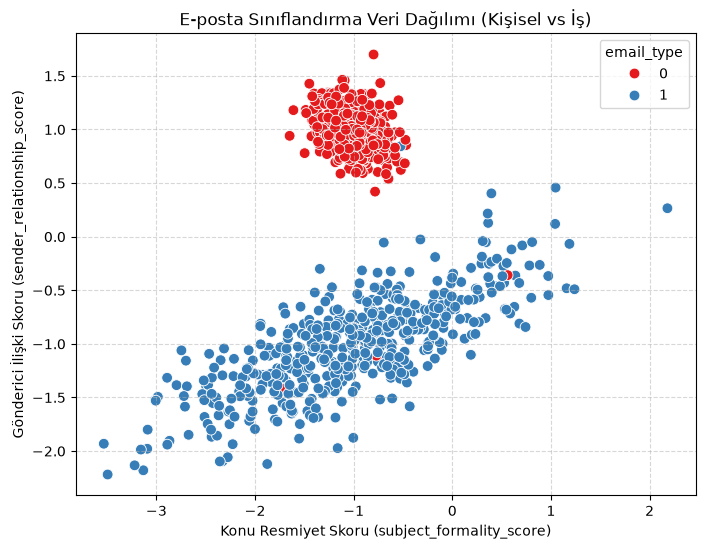

In [6]:
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=df['subject_formality_score'],
    y=df['sender_relationship_score'],
    hue=df['email_type'],
    palette="Set1",
    s=60
)
plt.title("E-posta Sınıflandırma Veri Dağılımı (Kişisel vs İş)")
plt.xlabel("Konu Resmiyet Skoru (subject_formality_score)")
plt.ylabel("Gönderici İlişki Skoru (sender_relationship_score)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


## 3. Özellik (X) ve Hedef (y) Ayrımı & PyTorch Tenzörlerine Dönüştürme

> [!IMPORTANT]
> **PyTorch Tenzör Gereksinimleri:**
> 1. **Veri Tipi (`dtype`):** Katman ağırlıkları varsayılan olarak `float32` olduğu için veriler `torch.float32` yapılmalıdır.
> 2. **Boyut Uyumu (`unsqueeze(1)`):** Skalar etiketlerin (1D array) boyutu `(N,)` halinden `nn.BCEWithLogitsLoss` beklentisi olan 2D `(N, 1)` haline getirilmelidir.


In [7]:
# 1. Pandas DataFrame'den NumPy matrislerine geçiş
X = df[["subject_formality_score", "sender_relationship_score"]].values  # Girdiler (2 Özellik)
y = df["email_type"].values                                              # Hedef Etiket (0 veya 1)

print(f"X boyutu: {X.shape} | y boyutu: {y.shape}")


X boyutu: (1000, 2) | y boyutu: (1000,)


In [8]:
from sklearn.model_selection import train_test_split

# %80 Eğitim (Train), %20 Test olacak şekilde veriyi bölüyoruz
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Eğitim Kümesi Büyüklüğü (Train): {len(X_train)} örnek")
print(f"Test Kümesi Büyüklüğü (Test): {len(X_test)} örnek")


Eğitim Kümesi Büyüklüğü (Train): 800 örnek
Test Kümesi Büyüklüğü (Test): 200 örnek


In [9]:
# NumPy dizilerini PyTorch float32 Tenzörlerine dönüştürme
X_train = torch.tensor(X_train, dtype=torch.float32)   # Shape: (800, 2)
X_test  = torch.tensor(X_test,  dtype=torch.float32)   # Shape: (200, 2)

# Hedef etiketleri 2D sütun vektörüne çevirme (unsqueeze(1))
y_train = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)  # Shape: (800, 1)
y_test  = torch.tensor(y_test,  dtype=torch.float32).unsqueeze(1)  # Shape: (200, 1)

print("Tenzör Boyutları:")
print(f"X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"X_test : {X_test.shape}  | y_test : {y_test.shape}")


Tenzör Boyutları:
X_train: torch.Size([800, 2]) | y_train: torch.Size([800, 1])
X_test : torch.Size([200, 2])  | y_test : torch.Size([200, 1])


## 4. PyTorch Sınıflandırma Modelinin Tanımlanması (`nn.Module`)

Bu modelde 2 doğrusal katman (`nn.Linear`) kullanıyoruz:
- **`layer_1`**: 2 girdi özelliğini alır (`in_features=2`), 5 gizli nöron üretir (`out_features=5`).
- **`layer_2`**: 5 gizli nöronu alır (`in_features=5`), 1 ham lojit (logit) çıktısı verir (`out_features=1`).

> [!WARNING]
> Bu aşamada katmanlar arasında **hiçbir Aktivasyon Fonksiyonu (ReLU vb.) KULLANMIYORUZ**.
> İki doğrusal katmanın arka arkaya dizilmesi matematiksel olarak tek bir doğrusal katmana eşdeğerdir:
> $$W_2 \cdot (W_1 \cdot X + b_1) + b_2 = (W_2 W_1) X + (W_2 b_1 + b_2) = W_{\text{eff}} X + b_{\text{eff}}$$
> Bu model sadece **Doğrusal (Linear) Karar Sınırı (Çizgi)** çizebilir.


In [10]:
from torch import nn

class ClassificationModel(nn.Module):
    def __init__(self):
        super().__init__()
        # 1. Katman: 2 girdi -> 5 gizli nöron
        self.layer_1 = nn.Linear(in_features=2, out_features=5)
        # 2. Katman: 5 gizli nöron -> 1 çıktı (Lojit)
        self.layer_2 = nn.Linear(in_features=5, out_features=1)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # İleri yayılım: Veri sırasıyla layer_1 ve layer_2'den geçer
        return self.layer_2(self.layer_1(x))

# Model nesnesini oluştur
model_0 = ClassificationModel()
print("Model Mimarisi:")
print(model_0)


Model Mimarisi:
ClassificationModel(
  (layer_1): Linear(in_features=2, out_features=5, bias=True)
  (layer_2): Linear(in_features=5, out_features=1, bias=True)
)


## 5. Kayıp Fonksiyonu (Loss Function), Optimizasyon ve Başarı Metriği

### 💡 Neden `nn.BCEWithLogitsLoss()` Seçtik?
1. **`nn.BCELoss()`**: Girdi olarak önceden `torch.sigmoid()` uygulanmış **olasılıkları** $[0, 1]$ bekler.
2. **`nn.BCEWithLogitsLoss()`**: Girdi olarak modelin ürettiği **ham lojitleri (raw logits)** $(-\infty, +\infty)$ bekler.
   * İçerisinde Sigmoid ve Binary Cross Entropy işlemlerini **Log-Sum-Exp hilesi** ile birleştirdiği için sayısal olarak **çok daha kararlıdır (numerically stable)** ve patlamaları önler.


In [11]:
# Kayıp Fonksiyonu: Binary Cross Entropy with Logits
loss_fn = nn.BCEWithLogitsLoss()

# Optimizasyon Algoritması: Stochastic Gradient Descent (SGD)
optimizer = torch.optim.SGD(params=model_0.parameters(), lr=0.01)

# Manuel Doğruluk (Accuracy) Metriği Fonksiyonu
def calculate_accuracy(y_true: torch.Tensor, y_pred: torch.Tensor) -> float:
    """Gerçek etiketler ile tahmin edilen etiketler arasındaki doğruluk yüzdesini hesaplar."""
    correct = torch.eq(y_true, y_pred).sum().item()  # Eşit olan elemanların toplamı
    acc = (correct / len(y_pred)) * 100
    return acc


## 6. Sınıflandırmada Tahmin Mantığı: Logits $\rightarrow$ Sigmoid $\rightarrow$ Pred Labels

Model eğitilmeden önce ürettiği ham çıktıları adım adım inceliyoruz:

```
    [ Model ] ──> Raw Logits (-inf, +inf) 
                      │
              torch.sigmoid()
                      ▼
               Pred Probs [0.0, 1.0] 
                      │
               torch.round()  ( Threshold = 0.5 )
                      ▼
               Pred Labels {0, 1}
```


In [12]:
# Eğitilmemiş modelden ilk 5 test örneği için tahmin alıyoruz
y_logits = model_0(X_test)[:5]
print("1. Ham Lojitler (Raw Logits):\n", y_logits)


1. Ham Lojitler (Raw Logits):
 tensor([[-0.0837],
        [ 1.0006],
        [ 0.1271],
        [ 0.5445],
        [-0.0681]], grad_fn=<SliceBackward0>)


In [13]:
# Lojitleri Sigmoid fonksiyonundan geçirerek 0 ile 1 arasında olasılıklara dönüştürüyoruz
y_pred_probs = torch.sigmoid(y_logits)
print("2. Olasılık Değerleri (Prediction Probabilities):\n", y_pred_probs)


2. Olasılık Değerleri (Prediction Probabilities):
 tensor([[0.4791],
        [0.7312],
        [0.5317],
        [0.6329],
        [0.4830]], grad_fn=<SigmoidBackward0>)


In [14]:
# Olasılıkları 0.5 eşik değerine (threshold) göre 0 veya 1 sınıf etiketlerine yuvarlıyoruz
# >= 0.5 ise 1 (İş e-postası), < 0.5 ise 0 (Kişisel e-posta)
y_preds = torch.round(y_pred_probs)
print("3. Tahmin Edilen Sınıf Etiketleri (Prediction Labels):\n", y_preds)
print("\nGerçek Etiketler (True Labels):\n", y_test[:5])


3. Tahmin Edilen Sınıf Etiketleri (Prediction Labels):
 tensor([[0.],
        [1.],
        [1.],
        [1.],
        [0.]], grad_fn=<RoundBackward0>)

Gerçek Etiketler (True Labels):
 tensor([[0.],
        [1.],
        [0.],
        [1.],
        [0.]])


In [15]:
# Eğitimsiz modelin ilk 5 örnek üzerindeki doğruluğu
print(f"Eğitimsiz İlk 5 Doğruluk Skoru: %{calculate_accuracy(y_test[:5], y_preds):.2f}")


Eğitimsiz İlk 5 Doğruluk Skoru: %80.00


## 7. Model Eğitim Döngüsü (Training Loop - 100 Epoch)

100 epoch boyunca standart 5 adımlı PyTorch eğitim döngüsünü çalıştırıyoruz.


In [16]:
torch.manual_seed(42)
epochs = 100

for epoch in range(epochs):
    # --- 1. EĞİTİM MODU ---
    model_0.train()

    # İleri Yayılım (Raw Logits üretir)
    y_logits = model_0(X_train)
    
    # Metrik hesabı için Lojit -> Olasılık -> Etiket dönüşümü
    y_pred = torch.round(torch.sigmoid(y_logits))
  
    # Kayıp (Loss) Hesaplama: Raw Logits ve Gerçek Etiketler
    loss = loss_fn(y_logits, y_train)
    acc = calculate_accuracy(y_true=y_train, y_pred=y_pred)

    # Gradyanları Sıfırla
    optimizer.zero_grad()

    # Geri Yayılım (Backpropagation)
    loss.backward()

    # Parametre Güncelleme (Step)
    optimizer.step()

    # --- 2. DEĞERLENDİRME MODU (TEST) ---
    model_0.eval()
    with torch.inference_mode():
        # İleri Yayılım
        test_logits = model_0(X_test)
        test_pred = torch.round(torch.sigmoid(test_logits))
        
        # Test Kaybı ve Doğruluğu
        test_loss = loss_fn(test_logits, y_test)
        test_acc = calculate_accuracy(y_true=y_test, y_pred=test_pred)

    # Her 5 epoch'ta bir durumu ekrana yazdır
    if epoch % 5 == 0 or epoch == epochs - 1:
        print(f"Epoch: {epoch:3d} | Loss: {loss:.5f} | Acc: %{acc:.2f} | Test Loss: {test_loss:.5f} | Test Acc: %{test_acc:.2f}")


Epoch:   0 | Loss: 0.56215 | Acc: %83.88 | Test Loss: 0.55844 | Test Acc: %85.00
Epoch:   5 | Loss: 0.54940 | Acc: %89.12 | Test Loss: 0.54552 | Test Acc: %89.50
Epoch:  10 | Loss: 0.53704 | Acc: %92.62 | Test Loss: 0.53301 | Test Acc: %94.00
Epoch:  15 | Loss: 0.52504 | Acc: %94.50 | Test Loss: 0.52087 | Test Acc: %94.50
Epoch:  20 | Loss: 0.51338 | Acc: %95.38 | Test Loss: 0.50909 | Test Acc: %95.50
Epoch:  25 | Loss: 0.50204 | Acc: %95.50 | Test Loss: 0.49764 | Test Acc: %96.00
Epoch:  30 | Loss: 0.49101 | Acc: %95.75 | Test Loss: 0.48650 | Test Acc: %96.50
Epoch:  35 | Loss: 0.48028 | Acc: %95.75 | Test Loss: 0.47567 | Test Acc: %96.50
Epoch:  40 | Loss: 0.46982 | Acc: %95.88 | Test Loss: 0.46513 | Test Acc: %96.50
Epoch:  45 | Loss: 0.45963 | Acc: %95.88 | Test Loss: 0.45486 | Test Acc: %96.50
Epoch:  50 | Loss: 0.44970 | Acc: %95.88 | Test Loss: 0.44487 | Test Acc: %96.00
Epoch:  55 | Loss: 0.44002 | Acc: %95.88 | Test Loss: 0.43513 | Test Acc: %96.00
Epoch:  60 | Loss: 0.43059 |

## 8. Karar Sınırını (Decision Boundary) Görselleştirme

Bu aşamada eğitilen modelin uzaydaki iki sınıfı birbirinden nasıl bir çizgi ile ayırdığını matematiksel doğrusal denklem üzerinden çizdiriyoruz.

### 📐 Matematiksel İspat:
Modelimiz iki katmandan oluşur:
$$W_1 \in \mathbb{R}^{5 \times 2}, \quad b_1 \in \mathbb{R}^{5}$$
$$W_2 \in \mathbb{R}^{1 \times 5}, \quad b_2 \in \mathbb{R}^{1}$$

Aktivasyon fonksiyonu (ReLU) olmadığı için efektif ağırlık ve bias:
$$W_{\text{eff}} = W_2 \cdot W_1 = [w_1, w_2]$$
$$b_{\text{eff}} = W_2 \cdot b_1 + b_2$$

Karar sınırı denklemimiz ($w_1 x_1 + w_2 x_2 + b_{\text{eff}} = 0$):
$$x_2 = \frac{-(w_1 x_1 + b_{\text{eff}})}{w_2}$$


In [17]:
import numpy as np

def plot_linear_decision_boundary(model, X, y):
    """Eğitilmiş doğrusal sınıflandırma modelinin karar sınırını (çizgisini) çizer."""
    # Model katman ağırlıklarını ve biaslarını al
    W1 = model.layer_1.weight.detach().numpy()       # Shape: (5, 2)
    b1 = model.layer_1.bias.detach().numpy()         # Shape: (5,)
    W2 = model.layer_2.weight.detach().numpy()       # Shape: (1, 5)
    b2 = model.layer_2.bias.detach().numpy()[0]      # Shape: (1,)

    # Efektif Doğrusal Ağırlık ve Bias Hesaplama
    W_eff = W2 @ W1   # Shape: (1, 2)
    w1, w2 = W_eff[0] # x1 (subject_formality) ve x2 (sender_relationship) ağırlıkları

    b_eff = (W2 @ b1)[0] + b2  # Efektif Bias

    # X1 ekseni için veri aralığı
    x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    xs = np.linspace(x_min, x_max, 200)

    # Doğru denkleminden X2 hesaplama: w1*x1 + w2*x2 + b = 0 -> x2 = -(w1*x1 + b) / w2
    ys = -(w1 * xs + b_eff) / w2

    # Veri noktalarını çizdir
    plt.scatter(X[:, 0], X[:, 1], c=y.squeeze(), cmap=plt.cm.RdYlBu, s=40, edgecolors="k", alpha=0.8)
    # Karar Sınırı Çizgisi
    plt.plot(xs, ys, "k-", linewidth=3, label="Karar Sınırı (Decision Boundary)")
    plt.xlabel("Subject Formality Score")
    plt.ylabel("Sender Relationship Score")
    plt.xlim(x_min, x_max)
    plt.ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
    plt.legend()


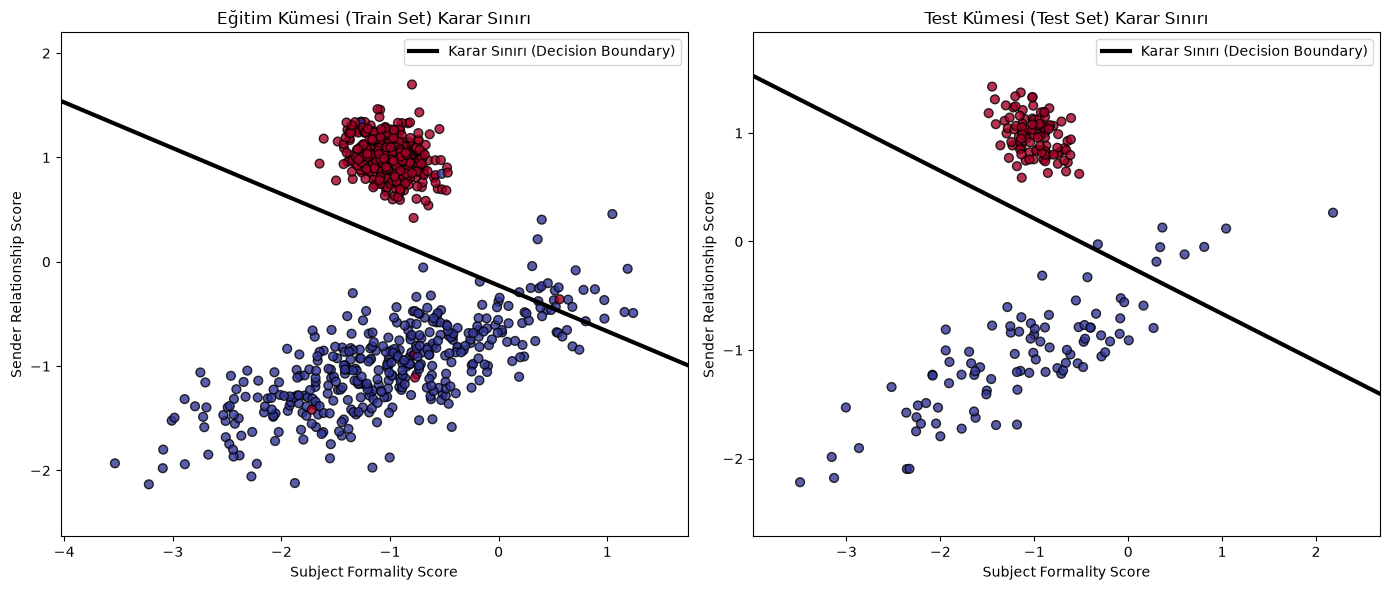

In [18]:
plt.figure(figsize=(14, 6))

# Train Karar Sınırı
plt.subplot(1, 2, 1)
plt.title("Eğitim Kümesi (Train Set) Karar Sınırı")
plot_linear_decision_boundary(model_0, X_train.numpy(), y_train.numpy())

# Test Karar Sınırı
plt.subplot(1, 2, 2)
plt.title("Test Kümesi (Test Set) Karar Sınırı")
plot_linear_decision_boundary(model_0, X_test.numpy(), y_test.numpy())

plt.tight_layout()
plt.show()


## 📝 Modül Özeti ve Önemli Çıkarımlar

| Kavram / Terim | Açıklama / Kural | PyTorch Kodu / Değeri |
| :--- | :--- | :--- |
| **Problem Tipi** | İkili Sınıflandırma (Binary Classification) | 0 (Personal) vs 1 (Work) |
| **Çıktı Boyutu** | Son katmanın nöron sayısı | `out_features = 1` |
| **Logits** | Modelin ham (raw) kısıtlanmamış çıktısı | `y_logits = model(X)` $(-\infty, +\infty)$ |
| **Olasılık (Probabilities)** | Lojitlerin 0 ile 1 arasına sıkıştırılması | `y_pred_probs = torch.sigmoid(y_logits)` |
| **Sınıf Etiketi (Labels)** | 0.5 eşik değerine göre yuvarlama | `y_preds = torch.round(y_pred_probs)` |
| **Kayıp Fonksiyonu** | Sayısal olarak kararlı Binary Cross Entropy | `nn.BCEWithLogitsLoss()` |
| **Aktivasyonsuz Ağ** | Aktivasyon fonksiyonu olmadan 100 katman da yapılsa model doğrusal (çizgi) kalır. | `Linear(2,5) -> Linear(5,1)` |

---
*Proje Rehberi: Atıl Samancıoğlu Derin Öğrenme Eğitimi Modül 08*
